# 05 · Clustering K-Means des profils alimentaires

**Objectif.** Regrouper les 174 zones selon leur profil alimentaire, nommer chaque groupe et en tirer des
recommandations pour le commanditaire.

**Variables** : les mêmes 5 indicateurs de régime que l'ACP (notebook 04), standardisés, car K-Means
travaille sur des distances : sans standardisation, les kcal (milliers) écraseraient les pourcentages.
La sous-nutrition n'entre pas dans le clustering : on regarde **ensuite** si les groupes en diffèrent.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RACINE / "reports" / "figures"
df = pd.read_csv(RACINE / "data" / "global_fao_dataset_impute.csv")

VARS = ["Kcal_veg", "Kcal_anim", "Part_kcal_cereales_pct", "Prot_total_g", "Part_prot_animal_pct"]
X = StandardScaler().fit_transform(df[VARS])

## 1. Choix du nombre de clusters : coude et silhouette

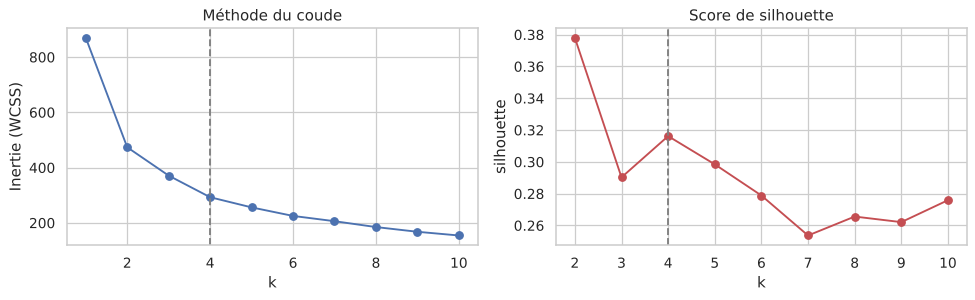

,1,2,3,4,5,6,7,8,9,10
inertie,870.00,473.62,371.07,292.87,256.05,225.13,206.05,184.85,167.76,154.33
silhouette,NaN,0.38,0.29,0.32,0.30,0.28,0.25,0.27,0.26,0.28


In [2]:
ks = range(1, 11)
inerties, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_) if k > 1 else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(ks, inerties, marker="o"); axes[0].set(title="Méthode du coude", xlabel="k", ylabel="Inertie (WCSS)")
axes[1].plot(ks, silhouettes, marker="o", color="#C44E52"); axes[1].set(title="Score de silhouette", xlabel="k", ylabel="silhouette")
for ax in axes: ax.axvline(4, ls="--", c="grey")
plt.tight_layout(); fig.savefig(FIG / "choix_k.png", dpi=120)
pd.DataFrame({"inertie": inerties, "silhouette": silhouettes}, index=list(ks)).round(3).T

**Choix : k = 4.** Le coude n'est pas net : l'inertie baisse fortement jusqu'à 4, puis plus lentement.
La silhouette départage : k = 2 a le meilleur score, mais ne fait qu'opposer « pays riches » et « pays
pauvres », ce qui n'apprend rien de neuf. Au-delà de 2, **k = 4 a la meilleure silhouette** (≈ 0,32,
contre 0,29 pour k = 3 et 0,30 pour k = 5). C'est aussi le nombre qui reste lisible pour un commanditaire.

## 2. Profil et nom de chaque cluster

In [3]:
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X)
df["cluster"] = km.labels_

profil = df.groupby("cluster").agg(
    zones=("Zone", "size"),
    kcal_total=("Kcal_total", "mean"),
    part_kcal_animal_pct=("Part_kcal_animal_pct", "mean"),
    part_kcal_cereales_pct=("Part_kcal_cereales_pct", "mean"),
    proteines_g=("Prot_total_g", "mean"),
    sous_nutrition_mediane_mesuree=("Taux_sous_nutrition_pct", "median"),
    zones_mesurees=("Taux_sous_nutrition_pct", "count"),
    sous_alimentes_mesures_M=("Sous_alimentation_millions", "sum"),
    population_M=("Population_millions", "sum"),
)

# Nommage à partir des profils (indépendant du numéro attribué par K-Means)
ordre = profil.sort_values("kcal_total").index.tolist()
noms = {}
noms[ordre[0]] = "1 · Régime céréalier pauvre"
intermediaire, riches = ordre[1], ordre[2:]
noms[intermediaire] = "2 · Transition alimentaire"
animal = profil.loc[riches, "part_kcal_animal_pct"].idxmax()
noms[animal] = "4 · Abondance, régime animal"
noms[[c for c in riches if c != animal][0]] = "3 · Abondance végétale et céréalière"
df["Profil"] = df["cluster"].map(noms)
profil.index = profil.index.map(noms)
profil = profil.sort_index()
profil.round(1)

,zones,kcal_total,part_kcal_animal_pct,part_kcal_cereales_pct,proteines_g,sous_nutrition_mediane_mesuree,zones_mesurees,sous_alimentes_mesures_M,population_M
cluster,,,,,,,,,
1 · Régime céréalier pauvre,49,2 396.00,7.70,52.60,59.80,21.30,46,479.80,2 716.80
2 · Transition alimentaire,57,2 724.70,21.10,36.50,77.00,9.20,33,104.70,1 034.20
3 · Abondance végétale et céréalière,24,3 201.20,14.60,46.40,91.00,5.50,15,157.50,1 955.90
"4 · Abondance, régime animal",44,3 316.40,29.70,28.10,105.50,5.00,2,1.70,1 290.50


In [4]:
for nom, g in df.groupby("Profil"):
    exemples = g.sort_values("Population_millions", ascending=False)["Zone"].head(8).str.replace(", continentale", "")
    print(f"{nom} ({len(g)} zones) : {', '.join(exemples)}…")
    print(f"   régions principales : {g['Region'].value_counts().head(3).to_dict()}\n")

1 · Régime céréalier pauvre (49 zones) : Inde, Indonésie, Nigéria, Bangladesh, Philippines, Éthiopie, Thaïlande, République-Unie de Tanzanie…
   régions principales : {'Afrique subsaharienne': 29, "Asie de l'Est et du Sud-Est": 7, 'Asie centrale et du Sud': 6}

2 · Transition alimentaire (57 zones) : Pakistan, Japon, Mexique, Viet Nam, Myanmar, Colombie, Ukraine, Soudan…
   régions principales : {'Amérique latine et Caraïbes': 25, 'Europe et Amérique du Nord': 8, "Asie de l'Est et du Sud-Est": 7}

3 · Abondance végétale et céréalière (24 zones) : Chine, Égypte, Iran (République islamique d'), Turquie, Afrique du Sud, République de Corée, Algérie, Maroc…
   régions principales : {"Afrique du Nord et Asie de l'Ouest": 12, 'Afrique subsaharienne': 5, 'Europe et Amérique du Nord': 2}

4 · Abondance, régime animal (44 zones) : États-Unis d'Amérique, Brésil, Fédération de Russie, Allemagne, France, Royaume-Uni, Italie, Espagne…
   régions principales : {'Europe et Amérique du Nord': 32, 'Océ

| Profil | Lecture |
|---|---|
| **1 · Régime céréalier pauvre** | Environ 2 400 kcal, moins de 8 % de calories animales, plus de la moitié des calories issues des céréales. Afrique subsaharienne, Asie du Sud et du Sud-Est (Inde, Bangladesh, Indonésie). Sous-nutrition médiane ≈ 21 %. |
| **2 · Transition alimentaire** | Environ 2 700 kcal, part animale autour de 20 %. Surtout Amérique latine et Asie du Sud-Est. Sous-nutrition ≈ 9 %. |
| **3 · Abondance végétale et céréalière** | Plus de 3 200 kcal, mais une part animale modérée : régime riche en céréales et en calories végétales (Maghreb, Moyen-Orient, Chine). Sous-nutrition ≈ 5 %. |
| **4 · Abondance, régime animal** | Plus de 3 300 kcal, près de 30 % de calories animales (Europe, Amérique du Nord, Océanie). Sous-nutrition très faible : seules 2 zones sur 44 ont un taux publié. |

## 3. Les profils diffèrent-ils en sous-nutrition ?

Test de Kruskal-Wallis sur les **taux mesurés** uniquement (les taux imputés dépendent des mêmes variables
que le clustering : les utiliser rendrait le test circulaire).

Kruskal-Wallis H = 40.3, p = 9.3e-09, n = 96


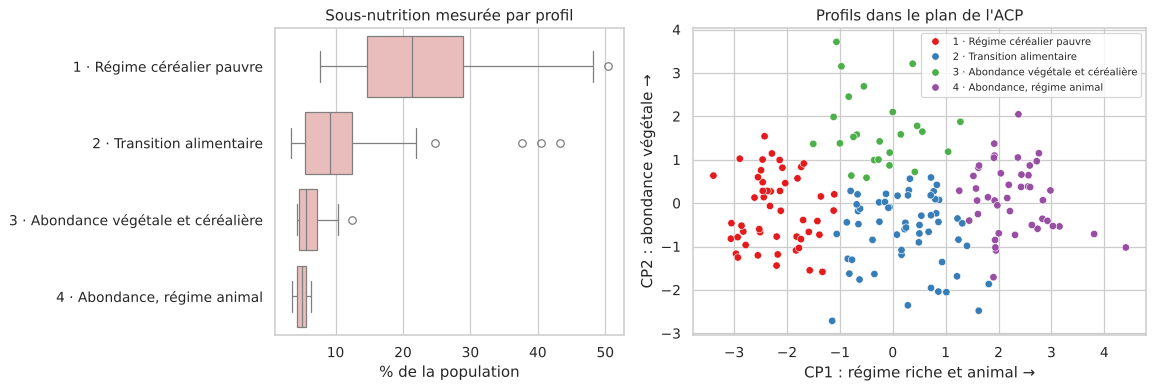

In [5]:
groupes = [g["Taux_sous_nutrition_pct"].dropna().values for _, g in df.groupby("Profil")]
kw = stats.kruskal(*groupes)
print(f"Kruskal-Wallis H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}, n = {sum(len(g) for g in groupes)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
sns.boxplot(data=df, x="Taux_sous_nutrition_pct", y="Profil", order=sorted(noms.values()), ax=axes[0], color="#F2B5B5")
axes[0].set(title="Sous-nutrition mesurée par profil", xlabel="% de la population", ylabel="")
pca = PCA(n_components=2).fit(X)
xy = pca.transform(X)
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=df["Profil"], hue_order=sorted(noms.values()), ax=axes[1], s=35, palette="Set1")
axes[1].set(title="Profils dans le plan de l'ACP", xlabel="CP1 : régime riche et animal →", ylabel="CP2 : abondance végétale →")
axes[1].legend(fontsize=8, title=None)
plt.tight_layout(); fig.savefig(FIG / "clusters.png", dpi=120)

**Lecture.** Les quatre profils, construits **sans** la sous-nutrition, ont des taux mesurés très différents
(p < 0,001) : le profil alimentaire est un bon outil de ciblage. Dans le plan de l'ACP, les profils se
succèdent le long de CP1, et CP2 sépare les deux profils d'abondance (végétale en haut, animale en bas).

In [6]:
import plotly.express as px

carte = df.sort_values("Profil")
fig = px.choropleth(carte, locations="ISO3", color="Profil", hover_name="Zone",
                    title="Profils alimentaires (K-Means, k = 4)")
fig.show()

<Figure plotly>

## 4. Recommandations pour le commanditaire

In [7]:
p1 = df[df["Profil"].str.startswith("1")]
print(f"Profil 1 : {len(p1)} zones, {p1['Population_millions'].sum():,.0f} millions d'habitants, "
      f"{p1['Sous_alimentation_millions'].sum():,.0f} millions de personnes sous-alimentées mesurées "
      f"({p1['Sous_alimentation_millions'].sum() / df['Sous_alimentation_millions'].sum() * 100:.0f} % du total mesuré)")
print("Pays du profil 1 avec le plus de personnes sous-alimentées :")
print(p1.nlargest(6, "Sous_alimentation_millions")[["Zone", "Sous_alimentation_millions", "Taux_sous_nutrition_pct"]].round(1).to_string(index=False))

Profil 1 : 49 zones, 2,717 millions d'habitants, 480 millions de personnes sous-alimentées mesurées (65 % du total mesuré)
Pays du profil 1 avec le plus de personnes sous-alimentées :
                       Zone  Sous_alimentation_millions  Taux_sous_nutrition_pct
                       Inde                       216.3                     17.3
                 Bangladesh                        26.1                     16.7
                   Éthiopie                        25.3                     26.9
                  Indonésie                        22.6                      9.0
République-Unie de Tanzanie                        16.4                     33.3
                Philippines                        14.0                     14.2


1. **Concentrer l'effort sur le profil 1 « régime céréalier pauvre ».** C'est là que la disponibilité
   calorique moyenne (≈ 2 400 kcal) reste sous le niveau où la sous-nutrition chute, et que vivent **65 %** des
   personnes sous-alimentées mesurées (480 millions, dont 216 millions en Inde). Leviers : augmenter la disponibilité (production, réduction des pertes
   après récolte, sécurisation des importations de céréales).
2. **Accompagner la diversification dans le profil 2 « transition ».** La quantité de calories s'y rapproche
   des besoins ; la part de protéines animales, deuxième variable liée à la sous-nutrition, reste à renforcer
   (légumineuses, élevage local, pêche).
3. **Combler les trous de données avant de décider.** 78 zones n'ont pas de taux mesuré ; les estimations du
   modèle (notebook 04) sont des ordres de grandeur, et les petits États insulaires sont les moins bien
   couverts (souvent « <0,1 million », qui ne dit presque rien de leur taux). Un indicateur moyen par pays masque aussi les inégalités internes : à compléter par
   des données infranationales (revenus, prix, conflits).

**Limites de l'analyse** : données de 2013 (bilans alimentaires) ; 29 zones sans bilan alimentaire, dont
plusieurs pays en crise (RD Congo, Somalie, Syrie, Soudan du Sud) ; corrélation n'est pas causalité.

In [8]:
df.to_csv(RACINE / "data" / "global_fao_dataset_clusters.csv", index=False)
print("Exporté : data/global_fao_dataset_clusters.csv")

Exporté : data/global_fao_dataset_clusters.csv
